## Graphing Frequencies of Words by Party

Using functions I made in frequency_functions.py

Each function takes parameter pattern and congress. 

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from frequency_functions import word_frequency, word_frequency_by_party

RAW = Path('../data/raw')
DERIVED = Path('../data/derived')
OUTPUT = Path('../figures')

colors = {'Democrat': '#1f4e9c', 'Republican': '#c8102e'}
plt.rcParams['savefig.dpi'] = 300


In [2]:
con = duckdb.connect(str(DERIVED / 'congress.duckdb'))

#### **Check that functions work**

In [3]:
congresses = list(range(43, 112))
abortion_pattern = r"(?i)\babortions?\b" # case insensitive, can be plural, and with word boundaries. 

rows = []
for value in congresses:
    rows.append(word_frequency(con, abortion_pattern, value))

abortion_total = pd.concat(rows, ignore_index=True)
display(abortion_total)


,congress,pattern,matches,words,frequency
0,43,(?i)\babortions?\b,6.0,8841805.0,0.006786
1,44,(?i)\babortions?\b,5.0,8632099.0,0.005792
2,45,(?i)\babortions?\b,3.0,8333418.0,0.003600
3,46,(?i)\babortions?\b,4.0,9970428.0,0.004012
4,47,(?i)\babortions?\b,6.0,11967998.0,0.005013
...,...,...,...,...,...
64,107,(?i)\babortions?\b,2451.0,29132867.0,0.841318
65,108,(?i)\babortions?\b,4945.0,31623275.0,1.563722
66,109,(?i)\babortions?\b,1881.0,29483784.0,0.637978
67,110,(?i)\babortions?\b,1276.0,32168915.0,0.396656


In [4]:
rows2 = []
for value in congresses:
    rows2.append(word_frequency_by_party(con, abortion_pattern, value))

abortion = pd.concat(rows2, ignore_index=True)
display(abortion)

,congress,pattern,party,matches,words,frequency
0,43,(?i)\babortions?\b,Republican,3.0,6468183.0,0.004638
1,43,(?i)\babortions?\b,Democrat,3.0,2373622.0,0.012639
2,44,(?i)\babortions?\b,Republican,1.0,4477709.0,0.002233
3,44,(?i)\babortions?\b,Democrat,4.0,4154390.0,0.009628
4,45,(?i)\babortions?\b,Republican,2.0,4185354.0,0.004779
...,...,...,...,...,...,...
133,109,(?i)\babortions?\b,Democrat,690.0,16370423.0,0.421492
134,110,(?i)\babortions?\b,Republican,966.0,14118461.0,0.684211
135,110,(?i)\babortions?\b,Democrat,310.0,18050454.0,0.171741
136,111,(?i)\babortions?\b,Republican,2472.0,12806953.0,1.930202


In [5]:
con.close()

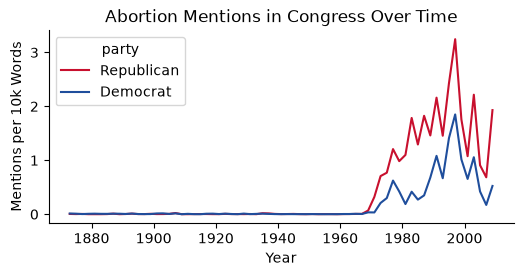

In [6]:
fig, ax = plt.subplots(figsize=(6, 2.5))
abortion['year'] = 1789 + 2* (abortion['congress'] - 1)
abortion.head()

sns.lineplot(
    data=abortion,
    x='year',
    y='frequency',
    hue='party',
    palette=colors,
    ax=ax,
)
ax.set(
    xlabel = 'Year', 
    ylabel = 'Mentions per 10k Words',
    title = 'Abortion Mentions in Congress Over Time'
)
ax.spines[['top', 'right']].set_visible(False) # drop the box lines, as in lecture

fig.savefig(OUTPUT / 'abortion_by_party.png')
